# Find Niches with Hexagonal Neighborhoods

A [`NeighborhoodCollection`](../../python/nbhd/api.md) holds neighborhoods
with their geometry and the feature spaces calculated for them. This brief
example covers a **simulated** tissue with a regular grid of hexagons,
calculates each hexagon's cell-type composition, clusters the hexagons by
composition, and maps the clusters back onto the tissue as niches. The
simulation has three zones: a tumor core, an immune border around it, and
stroma.

In [1]:
import anndata as ad
import numpy as np
import pandas as pd

import celldega as dega

## Simulate a tissue

In [2]:
rng = np.random.default_rng(0)

cell_types = ["Tumor", "T cells", "Macrophages", "Fibroblasts", "Endothelial"]
zone_mix = {
    "tumor core": [0.75, 0.05, 0.10, 0.05, 0.05],
    "immune border": [0.20, 0.40, 0.25, 0.10, 0.05],
    "stroma": [0.05, 0.05, 0.10, 0.60, 0.20],
}

n_cells = 8000
xy = rng.uniform(0, 1000, (n_cells, 2))  # microns
distance = np.hypot(xy[:, 0] - 500, xy[:, 1] - 500)
zone = np.where(distance < 250, "tumor core", np.where(distance < 380, "immune border", "stroma"))
cell_type = [rng.choice(cell_types, p=zone_mix[z]) for z in zone]

adata = ad.AnnData(
    obs=pd.DataFrame(
        {"cell_type": pd.Categorical(cell_type, categories=cell_types)},
        index=[f"cell_{i}" for i in range(n_cells)],
    )
)
adata.obsm["spatial"] = xy
adata

AnnData object with n_obs × n_vars = 8000 × 0
    obs: 'cell_type'
    obsm: 'spatial'

## Build hexagonal neighborhoods and their composition

`generate_hextile` covers the tissue with 80 µm hexagons, and
`calc_nbhd_by_pop` calculates each hexagon's cell-type proportions, keeping
hexagons with at least 5 cells. The collection stores the hexagons and their
composition together.

In [3]:
gdf_hex = dega.nbhd.generate_hextile(adata, diameter=80)
population = dega.nbhd.calc_nbhd_by_pop(adata, gdf_hex, category="cell_type", min_cells=5)

hexagons = dega.nbhd.NeighborhoodCollection(gdf=gdf_hex, nbhd_type="hextile")
hexagons.subset(population.obs_names)  # drop hexagons with too few cells
hexagons.add_mod("population", population)
hexagons.mod["population"]

AnnData object with n_obs × n_vars = 265 × 5
    obs: 'neighborhood_id', 'name', 'neighborhood_type', 'method', 'area', 'area_um2', 'centroid_x', 'centroid_y', 'n_cells', 'cell_type'
    var: 'cell_type', 'entity_type'
    uns: 'category', 'output', 'axis_entities'

## Cluster the hexagons by composition

Columns are hexagons and rows are cell types. Cutting the column dendrogram into
three groups gives each hexagon a niche.

In [4]:
mat = dega.clust.Matrix(mdata=hexagons, color_by="population")
mat.cluster()
niche = mat.cut_tree(axis="col", n_clusters=3)
hexagons.obs["niche"] = niche.reindex(hexagons.obs.index).astype(str)

# Show the niches as a column category in the Clustergram.
hexagons.mod["population"].obs["niche"] = hexagons.obs["niche"]
mat = dega.clust.Matrix(mdata=hexagons, color_by="population", col_attr=["niche"])
mat.cluster()
cgm = dega.viz.Clustergram(matrix=mat, width=500, height=300, row_label_scale=0.3)

In [5]:
cgm

## Map the niches onto the tissue

The niches recover the three simulated zones: the core, the border around it,
and the stroma.

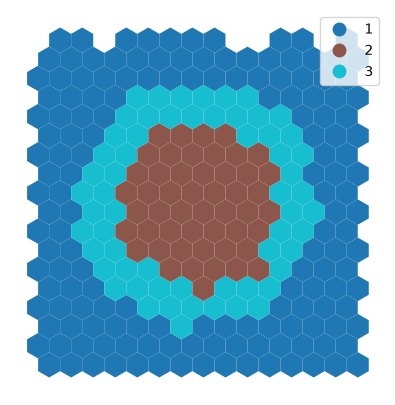

In [6]:
ax = hexagons.gdf.assign(niche=hexagons.obs["niche"]).plot(
    column="niche", categorical=True, legend=True, figsize=(5, 5)
)
ax.set_axis_off()

Each niche's composition tells you what it is:

In [7]:
hexagons.mod["population"].to_df().groupby(hexagons.obs["niche"]).mean().round(2)

cell_type,Tumor,T cells,Macrophages,Fibroblasts,Endothelial
niche,,,,,
1,0.05,0.06,0.10,0.60,0.19
2,0.69,0.10,0.11,0.06,0.04
3,0.20,0.35,0.24,0.14,0.06
